<center><h1>Chen_Jessica_HW6</h1></center>

Name: Jessica Chen
<br>
Github Username: jc6006 
<br>
USC ID: 9760667304

## 1. Tree-Based Methods

Import packages

In [124]:
import pandas as pd, numpy as np, seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
FIXED_SEED=0

### (a) Download the APS Failure data

In [114]:
def read_aps(path):
    with open(path) as f:
        skip = next(i for i, line in enumerate(f) if line.startswith("class"))
    return pd.read_csv(path,skiprows=skip,na_values="na")
train_raw=read_aps("../data/APS_data/aps_failure_training_set.csv")
test_raw=read_aps("../data/APS_data/aps_failure_test_set.csv")
y_train=(train_raw["class"]=="pos").astype(int)
y_test=(test_raw["class"]=="pos").astype(int)
x_train_raw=train_raw.drop(columns="class")
x_test_raw=test_raw.drop(columns="class")

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

#### Deletion:
- Delete full rows with missing data (can result in data loss)
- Just ignore missing data for interpretations (complicates relationships)
#### Imputation:
- Mean/median/mode imputation where the missing data is replaced by mean/median/mode
- Regression imputation where a regression model is fitted to predict
- KNN imputation where KNN is used to predict
- Multiple Imputation by Chained Equations (MICE) where multiple datasets are made to predict the value and then pooled for a final estimate

##### choosing **median imputation**

#### (ii) Calculate the coefficient of variation

In [115]:
def impute_median(a):
    return a.fillna(a.median()).fillna(0)
x_train=impute_median(x_train_raw)
x_test=impute_median(x_test_raw)

#### (iii) Plot a correlation matrix

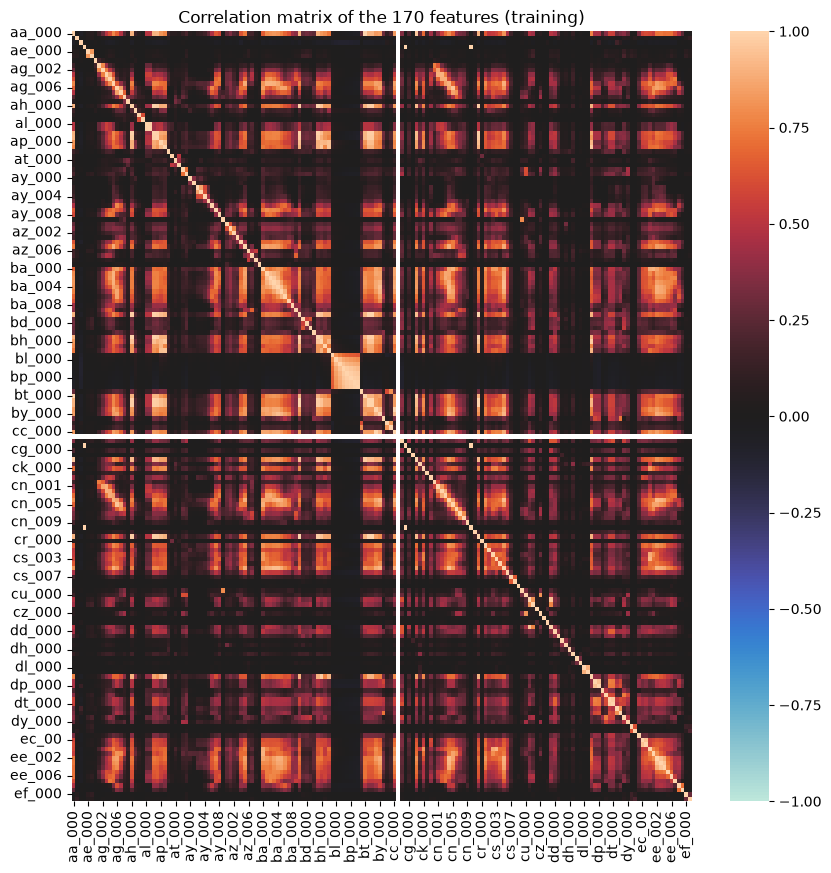

In [116]:
cv = (x_train.std() / x_train.mean()).replace([np.inf, -np.inf], np.nan)
cv_abs = cv.abs().dropna()
corr = x_train.corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr, center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix of the 170 features (training)")
plt.show()

#### (iv) Make scatter plots and box plots

13 features with highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


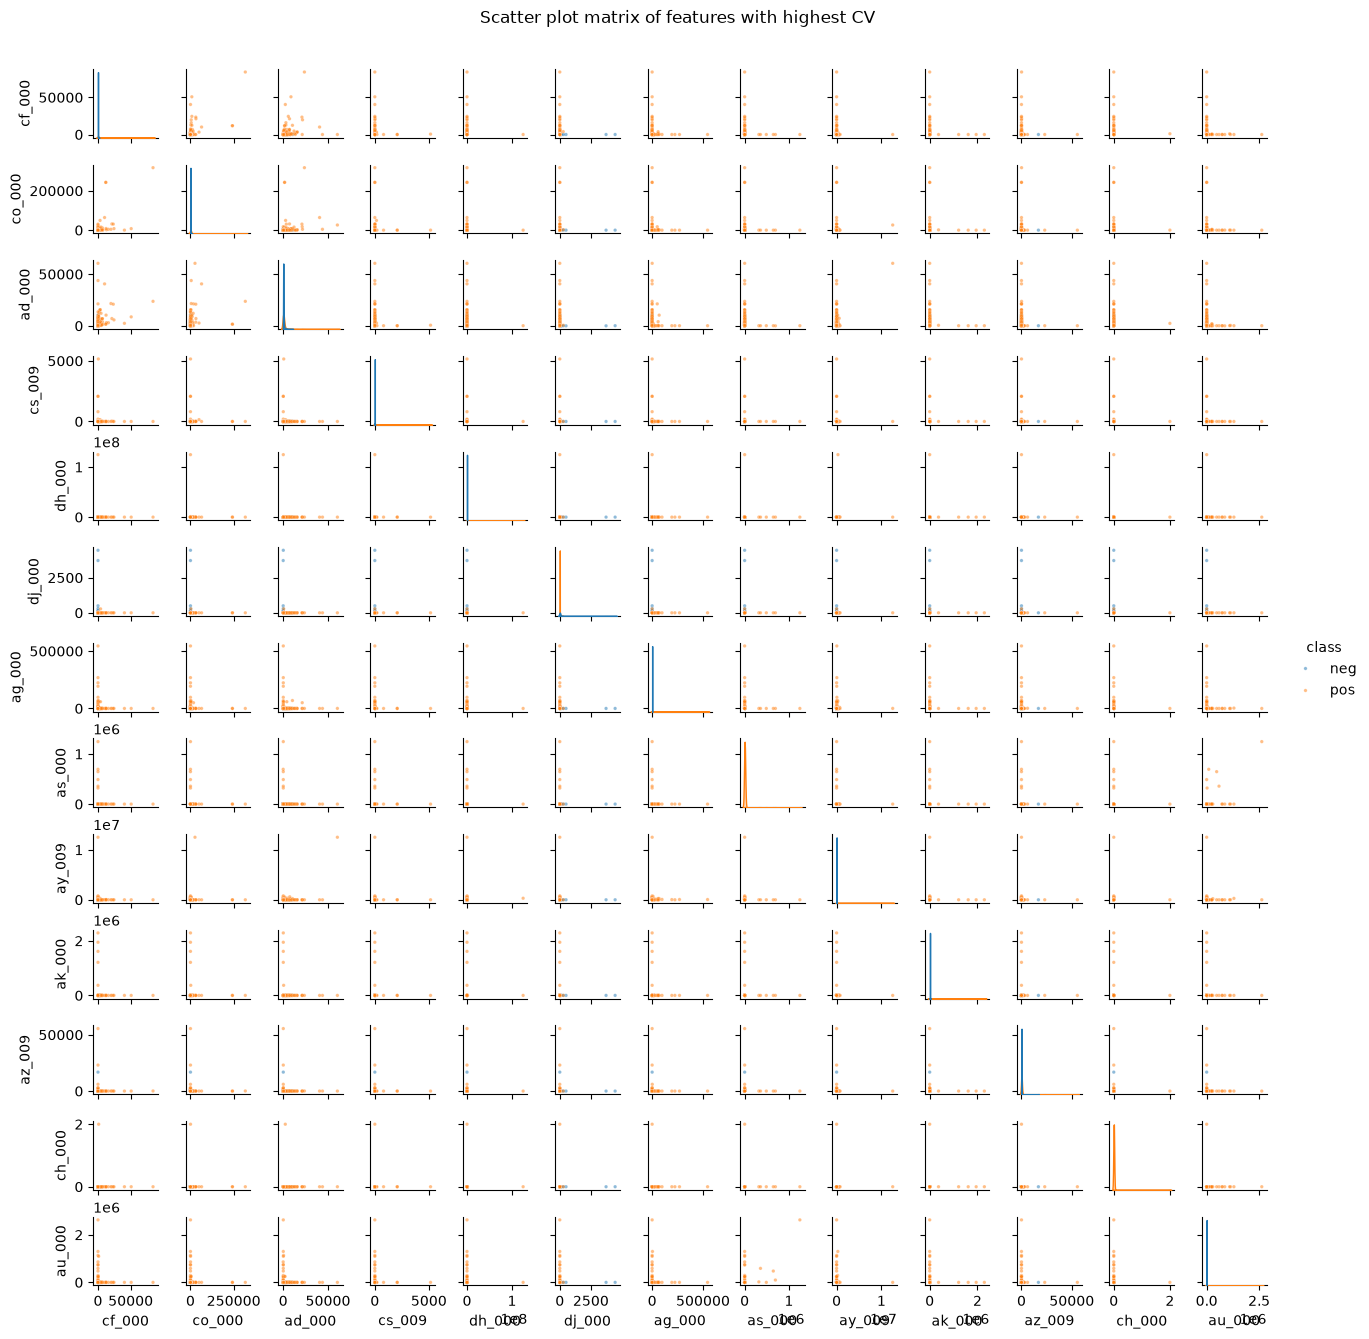

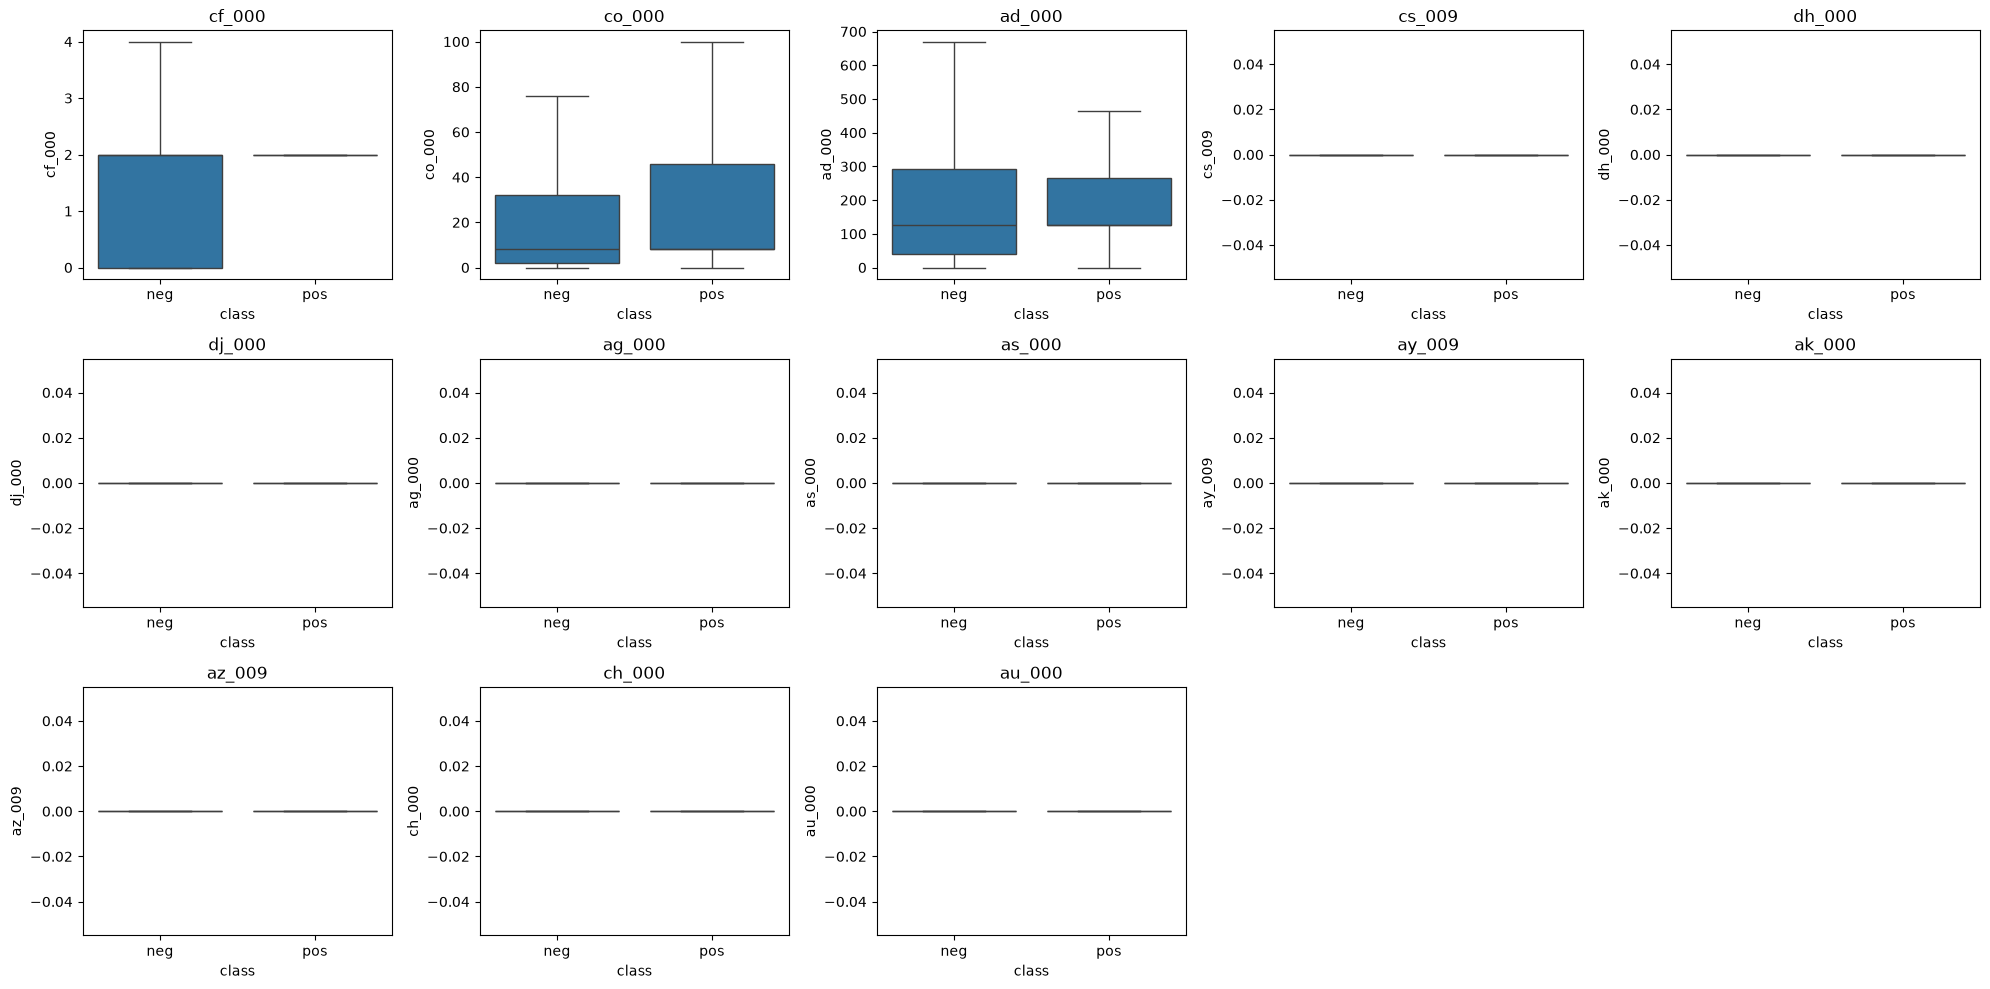

In [117]:
k=13
top_feats=cv_abs.sort_values(ascending=False).head(k).index.tolist()
print(k,"features with highest CV:",top_feats)
plot_df=x_train[top_feats].copy()
plot_df["class"]=y_train.map({0:"neg",1:"pos"})
sample=pd.concat([plot_df[plot_df["class"]=="neg"].sample(1000, random_state=FIXED_SEED),plot_df[plot_df["class"]=="pos"]])
g=sns.pairplot(sample,hue="class",vars=top_feats,plot_kws={"s":6,"alpha":0.5},height=1)
g.fig.suptitle("Scatter plot matrix of features with highest CV", y=1.03)
plt.show()

fig,axes=plt.subplots(3,5,figsize=(20, 10))
for ax,f in zip(axes.ravel(),top_feats):
    sns.boxplot(x="class",y=f,data=plot_df,ax=ax,showfliers=False,order=["neg","pos"])
    ax.set_title(f)
for ax in axes.ravel()[len(top_feats):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Not really, it's too difficult to tell with how many negative data points are shown in every scatterplot.

#### (v) Is this data set imbalanced?

In [118]:
print("Training set:", y_train.value_counts().rename({0:"negative",1:"positive"}).to_dict())
print("Test set:", y_test.value_counts().rename({0:"negative",1:"positive"}).to_dict())

Training set: {'negative': 59000, 'positive': 1000}
Test set: {'negative': 15625, 'positive': 375}


Yes, the data is mostly negative in both the training and test sets.

### (c) Train a random forest

[RF (no balancing)] train: misclassification = 0.0000%, AUC = 1.0000
          pred neg  pred pos
true neg     59000         0
true pos         0      1000 

[RF (no balancing)] test: misclassification = 0.7437%, AUC = 0.9944
          pred neg  pred pos
true neg     15608        17
true pos       102       273 



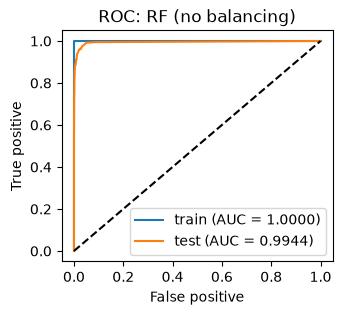

Out of Bag error estimate: 0.6167%  vs.  test error: 0.7437%


In [119]:
results =[]
def evaluate(model,name,xtr,ytr,xte,yte):
    out={"model":name}
    plt.figure(figsize=(3.5,3))
    for split,x,y in [("train",xtr,ytr),("test",xte,yte)]:
        prob=model.predict_proba(x)[:,1]
        pred=(prob>=0.5).astype(int)
        auc=roc_auc_score(y,prob)
        cm=confusion_matrix(y,pred,labels=[0,1])
        fpr,tpr,_=roc_curve(y,prob)
        mis=1-accuracy_score(y,pred)
        plt.plot(fpr,tpr,label=f"{split} (AUC = {auc:.4f})")
        print(f"[{name}] {split}: misclassification = {mis:.4%}, AUC = {auc:.4f}")
        print(pd.DataFrame(cm,index=["true neg","true pos"],columns=["pred neg","pred pos"]),"\n")
        out[f"{split}_misclass"],out[f"{split}_auc"]=mis,auc
        out[f"{split}_FP"],out[f"{split}_FN"]=cm[0, 1],cm[1, 0]
    plt.plot([0,1],[0,1],"k--")
    plt.xlabel("False positive");plt.ylabel("True positive")
    plt.title(f"ROC: {name}"); plt.legend(loc="lower right"); plt.show()
    results.append(out)
    return out

rf=RandomForestClassifier(oob_score=True,n_jobs=-1,random_state=FIXED_SEED)
rf.fit(x_train, y_train)
rf_res=evaluate(rf,"RF (no balancing)",x_train,y_train,x_test,y_test)
oob_err=1-rf.oob_score_
print(f"Out of Bag error estimate: {oob_err:.4%}  vs.  test error: {rf_res['test_misclass']:.4%}")
results[-1]["oob_error"]=oob_err

### (d) Research class imbalance in random forest

Class weighting (assign a higher weight to misclassifications of the minority class & lower weight to majority class), Balanced Random Forest, oversample minority class, SMOTE (generate synthetic minority instances)

[RF (class_weight balanced)] train: misclassification = 0.0000%, AUC = 1.0000
          pred neg  pred pos
true neg     59000         0
true pos         0      1000 

[RF (class_weight balanced)] test: misclassification = 1.0563%, AUC = 0.9922
          pred neg  pred pos
true neg     15607        18
true pos       151       224 



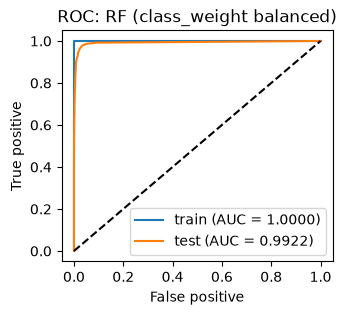

Out of Bag error estimate: 0.7717%  vs.  test error: 1.0563%


In [120]:
rf_bal=RandomForestClassifier(oob_score=True,class_weight="balanced_subsample",n_jobs=-1,random_state=FIXED_SEED)
rf_bal.fit(x_train, y_train)
rfb_res=evaluate(rf_bal,"RF (class_weight balanced)",x_train,y_train,x_test,y_test)
oob_err_bal=1-rf_bal.oob_score_
print(f"Out of Bag error estimate: {oob_err_bal:.4%}  vs.  test error: {rfb_res['test_misclass']:.4%}")
results[-1]["oob_error"]=oob_err_bal

### (e) XGBoost and Model Trees

         cv_auc  cv_error
alpha                    
0.0    0.988491  0.006367
0.1    0.987799  0.006750
1.0    0.987617  0.006300
10.0   0.978468  0.008517
100.0  0.978324  0.012267
Best alpha: 0.0
[XGBoost(no balancing)] train: misclassification = 0.0017%, AUC = 1.0000
          pred neg  pred pos
true neg     59000         0
true pos         1       999 

[XGBoost(no balancing)] test: misclassification = 0.6812%, AUC = 0.9932
          pred neg  pred pos
true neg     15603        22
true pos        87       288 



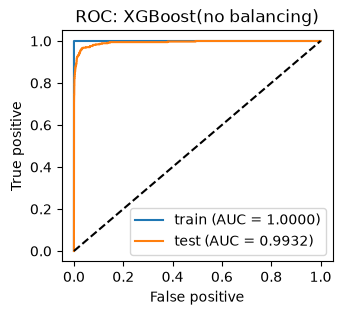

5-fold CV error: 0.6367%  vs.  test error: 0.6812%


In [121]:
alphas=[0,0.1,1,10,100]
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=FIXED_SEED)
def make_xgb(alpha):
    return XGBClassifier(reg_alpha=alpha,objective="binary:logistic",eval_metric="logloss",random_state=FIXED_SEED)
def cv_alpha(x,y,alphas,use_smote=False):
    scores={a:{"auc":[],"err":[]} for a in alphas}
    for tr,va in skf.split(x,y):
        xtr,ytr = x.iloc[tr],y.iloc[tr]
        if use_smote:
            xtr,ytr=SMOTE(random_state=FIXED_SEED).fit_resample(xtr, ytr)
        for a in alphas:
            m=make_xgb(a).fit(xtr,ytr)
            p=m.predict_proba(x.iloc[va])[:,1]
            scores[a]["auc"].append(roc_auc_score(y.iloc[va],p))
            scores[a]["err"].append(1 - accuracy_score(y.iloc[va],(p >= 0.5).astype(int)))
    table=pd.DataFrame({a:{"cv_auc":np.mean(s["auc"]),"cv_error":np.mean(s["err"])} for a,s in scores.items()}).T
    table.index.name="alpha"
    return table
cv_table_e=cv_alpha(x_train,y_train,alphas)
best_alpha_e=cv_table_e["cv_auc"].idxmax()
print(cv_table_e)
print("Best alpha:",best_alpha_e)
xgb_e=make_xgb(best_alpha_e).fit(x_train,y_train)
xgb_res=evaluate(xgb_e,"XGBoost(no balancing)",x_train,y_train,x_test,y_test)
results[-1]["cv_error"]=cv_table_e.loc[best_alpha_e,"cv_error"]
print(f"5-fold CV error: {results[-1]['cv_error']:.4%}  vs.  test error: {xgb_res['test_misclass']:.4%}")

### (f) Use SMOTE to pre-process your data

         cv_auc  cv_error
alpha                    
0.0    0.989343  0.006200
0.1    0.988201  0.006650
1.0    0.989362  0.006633
10.0   0.988548  0.008183
100.0  0.984658  0.017550
Best alpha: 1.0
After SMOTE: {0: 59000, 1: 59000}
[XGBoost+SMOTE] train: misclassification = 0.0017%, AUC = 1.0000
          pred neg  pred pos
true neg     59000         0
true pos         1       999 

[XGBoost+SMOTE] test: misclassification = 0.7750%, AUC = 0.9930
          pred neg  pred pos
true neg     15556        69
true pos        55       320 



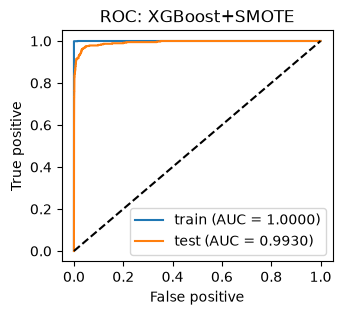

5-fold CV error: 0.6633%  vs.  test error: 0.7750%


,train_misclass,test_misclass,train_auc,test_auc,test_FP,test_FN,oob_error,cv_error
model,,,,,,,,
RF (no balancing),0.000000,0.007437,1.000000,0.994361,17,102,0.006167,NaN
RF (class_weight balanced),0.000000,0.010563,1.000000,0.992173,18,151,0.007717,NaN
XGBoost(no balancing),0.000017,0.006812,1.000000,0.993205,22,87,NaN,0.006367
XGBoost+SMOTE,0.000017,0.007750,0.999985,0.993040,69,55,NaN,0.006633


In [122]:
cv_table_f=cv_alpha(x_train,y_train,alphas,use_smote=True)
best_alpha_f=cv_table_f["cv_auc"].idxmax()
print(cv_table_f)
print("Best alpha:",best_alpha_f)
x_sm,y_sm=SMOTE(random_state=FIXED_SEED).fit_resample(x_train,y_train)
print("After SMOTE:",y_sm.value_counts().to_dict())
xgb_f=make_xgb(best_alpha_f).fit(x_sm,y_sm)
xgb_sm_res=evaluate(xgb_f,"XGBoost+SMOTE",x_train,y_train,x_test,y_test)
results[-1]["cv_error"]=cv_table_f.loc[best_alpha_f,"cv_error"]
print(f"5-fold CV error: {results[-1]['cv_error']:.4%}  vs.  test error: {xgb_sm_res['test_misclass']:.4%}")
summary=pd.DataFrame(results).set_index("model")
summary[["train_misclass","test_misclass","train_auc","test_auc","test_FP","test_FN","oob_error","cv_error"]]

SMOTE is better for reducing false negatives but increases false positives. AUC values are similar.

## 2. ISLR 6.6.3

- iv. Increases s causes the model to be more flexible and fit better to the training data
- ii. Small s makes the model too rigid, large s makes it overfit
- iii. Variance increases because the model can vary more, depending on the data
- iv. A more flexible model can fit to the actual relationship more closely
- v. Not affected

## 3. ISLR 6.6.5

#### a)
y₁ - β₀ - β₁·x₁₁ - β₂·x₁₂)² + (y₂ - β₀ - β₁·x₂₁ - β₂·x₂₂)² + λ(β₁² + β₂²) <br>
minβ₁β₂ (y₁ - β₁·x₁₁ - β₂·x₁₂)² + (y₂ - β₁·x₂₁ - β₂·x₂₂)² + λ(β₁² + β₂²)
#### b)
(y − aβ₁ − aβ₂)² = (y − a(β₁+β₂))²          (−y + aβ₁ + aβ₂)² = (y − a(β₁+β₂))² <br>
f(β₁, β₂) = 2 (y - a(β₁+β₂))² + λ(β₁² + β₂²) <br>
δf/δβ₁ = -4a (y - a(β₁+β₂)) + 2λβ₁           δf/δβ₂ = -4a (y - a(β₁+β₂)) + 2λβ₂ <br>
2λβ₁ = 4a (y - a(β₁+β₂)) = 2λβ₂ 
β₁ = β₂ 
#### c)
minβ₁β₂ (y₁ - β₁·x₁₁ - β₂·x₁₂)² + (y₂ - β₁·x₂₁ - β₂·x₂₂)² + λ(|β₁| + |β₂|)
#### d)
RSS only depends on s = β₁ + β₂. For a given s, lasso just minimizes |β₁| + |β₂|. β₁ does not have to equal β₂. Solutions are all β₁ + β₂ = s with β₁, β₂ ≥ 0 if s ≥ 0 or β₁, β₂ ≤ 0 if s ≤ 0

## 4. ISLR 8.4.5

0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75. <br>
- Majority vote: red (4 values under 0.5, 6 values above 0.5)
- Average probability: green (0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75 summed and divided by 10 = 0.45, 0.45<0.5)

## 5. ISLR 9.7.3

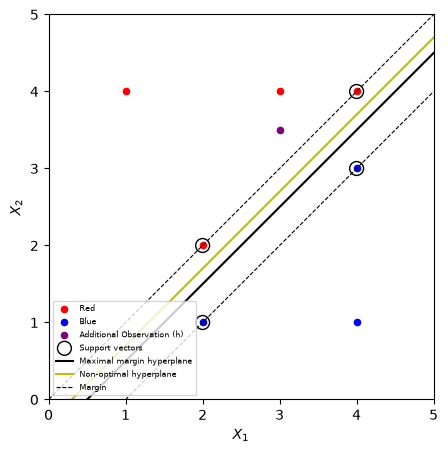

In [123]:
red=np.array([(3,4),(2,2),(4,4),(1,4)])
blue=np.array([(2,1),(4,3),(4,1)])
x=np.linspace(0,5,100)
plt.figure(figsize=(5,5))
plt.scatter(red[:,0],red[:,1],c="red",s=20,label="Red")
plt.scatter(blue[:,0],blue[:,1],c="blue",s=20,label="Blue")
plt.scatter([3], [3.5], c="purple", s=20, label="Additional Observation (h)")
support=np.array([(2,2),(4,4),(2,1),(4,3)])
plt.scatter(support[:,0],support[:,1],s=100,facecolors="none",edgecolors="black",label="Support vectors")
plt.plot(x,x-0.5,"k-",label="Maximal margin hyperplane")
plt.plot(x,x-0.3,"y-",label="Non-optimal hyperplane")
plt.plot(x,x,"k--",lw=0.8,label="Margin")
plt.plot(x,x-1,"k--",lw=0.8)
plt.xlim(0,5); plt.ylim(0,5)
plt.xlabel("$X_1$"); plt.ylabel("$X_2$")
plt.gca().set_aspect("equal")
plt.legend(fontsize=6, loc="lower left")
plt.show()

#### b)
0.5 - X1 + X2 = 0.
#### c)
Classify to red if 0.5 - X1 + X2 < 0 and blue otherwise.
β₀ = 0.5   β₁ = 1   β₂ = 1
#### f)
Seventh observation already lies outside the margin so movement of it wouldn't affect the hyperplane (only relies on support vectors).
#### g)
0.3 - X1 + X2 = 0.